# Cell 1: Import Libraries

In [24]:
# Import the required libraries for data analysis and visualization
import os
import glob
import warnings

# Ignore unnecessary warning messages
warnings.filterwarnings("ignore")

# Import libraries for numerical operations and data handling
import numpy as np
import pandas as pd

# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import functions for splitting the dataset and preprocessing features
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Import machine learning models
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Set the default visualization style
sns.set_theme(style="whitegrid")

# Set the default figure size for plots
plt.rcParams["figure.figsize"] = (8, 5)

# Display a confirmation message
print("All libraries imported successfully!")

All libraries imported successfully!


# Cell 2: Mount Google Drive

In [25]:
# Import the Google Drive module from Google Colab
from google.colab import drive

# Mount Google Drive to access the uploaded dataset
drive.mount('/content/drive')

# Display a confirmation message
print("Google Drive mounted successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive mounted successfully!


# Cell 3: Load the Iris Dataset

In [26]:
# Search for the Iris CSV file inside Google Drive
csv_files = glob.glob(
    "/content/drive/MyDrive/**/iris.csv",
    recursive=True
)

# Stop execution if the dataset cannot be found
if not csv_files:
    raise FileNotFoundError(
        "iris.csv was not found. Please check the file name and location."
    )

# Display all matching dataset paths
print("Available Iris dataset files:")

for i, path in enumerate(csv_files):
    print(f"{i}: {path}")

# Select the first matching dataset file
DATA_PATH = csv_files[0]

# Load the CSV dataset into a Pandas DataFrame
df = pd.read_csv(DATA_PATH)

# Display basic information about the loaded dataset
print("\nDataset loaded successfully!")
print("Dataset path:", DATA_PATH)
print("Dataset shape:", df.shape)

# Display the first five rows
display(df.head())

Available Iris dataset files:
0: /content/drive/MyDrive/iris.csv

Dataset loaded successfully!
Dataset path: /content/drive/MyDrive/iris.csv
Dataset shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


# Cell 4: Inspect the Dataset

In [27]:
# Display the first five records
print("First five rows of the dataset:")
display(df.head())

# Display the number of rows and columns
print("\nDataset shape:")
print(df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Display the data types of each column
print("\nData types:")
print(df.dtypes)

# Display dataset information, including non-null counts
print("\nDataset information:")
df.info()

# Check for missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# Count duplicate rows in the dataset
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# Display descriptive statistics for the dataset
print("\nStatistical summary:")
display(df.describe(include="all"))

First five rows of the dataset:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Dataset shape:
(150, 5)

Column names:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Data types:
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species          object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Number of duplicate rows:
1

Statistical summary:


,sepal_length,sepal_width,petal_length,petal_width,species
count,150.000000,150.000000,150.000000,150.000000,150
unique,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,setosa
freq,NaN,NaN,NaN,NaN,50
mean,5.843333,3.057333,3.758000,1.199333,NaN
std,0.828066,0.435866,1.765298,0.762238,NaN
min,4.300000,2.000000,1.000000,0.100000,NaN
25%,5.100000,2.800000,1.600000,0.300000,NaN
50%,5.800000,3.000000,4.350000,1.300000,NaN
75%,6.400000,3.300000,5.100000,1.800000,NaN


# Cell 5: Data Cleaning and Feature Selection

In [28]:
# Convert column names to lowercase and remove surrounding spaces
df.columns = df.columns.str.strip().str.lower()

# Remove duplicate records
df = df.drop_duplicates().reset_index(drop=True)

# Identify the target column containing the species labels
possible_targets = ["species", "target", "class", "variety"]

target_col = next(
    (col for col in possible_targets if col in df.columns),
    None
)

# Raise an error if no target column is found
if target_col is None:
    raise ValueError(
        f"Target column not found. Available columns: {df.columns.tolist()}"
    )

# Remove rows containing missing values for this baseline experiment
df = df.dropna().reset_index(drop=True)

# Separate input features from the target variable
X = df.drop(columns=[target_col])

# Keep only numeric input features
X = X.select_dtypes(include=np.number)

# Store the target labels separately
y = df[target_col]

# Ensure at least two numeric features are available
if X.shape[1] < 2:
    raise ValueError("At least two numeric features are required.")

# Display the selected features and target information
print("Target column:", target_col)
print("Input features:", X.columns.tolist())
print("Number of features:", X.shape[1])
print("Number of samples:", len(X))

# Display the number of samples in each species
print("\nClass distribution:")
print(y.value_counts())

# Display the cleaned dataset
display(df.head())

Target column: species
Input features: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
Number of features: 4
Number of samples: 149

Class distribution:
species
setosa        50
versicolor    50
virginica     49
Name: count, dtype: int64


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


# Cell 6: Visualize Class Distribution

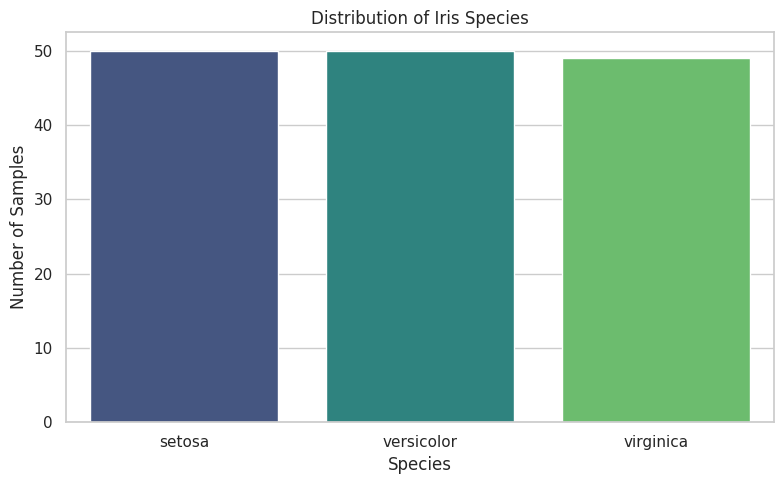

In [29]:
# Create a count plot to show the number of samples in each species
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x=target_col,
    hue=target_col,
    palette="viridis",
    legend=False
)

# Add a descriptive title and axis labels
plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Number of Samples")

# Adjust the layout to prevent overlapping elements
plt.tight_layout()

# Display the plot
plt.show()

# Cell 7: Visualize Feature Distributions

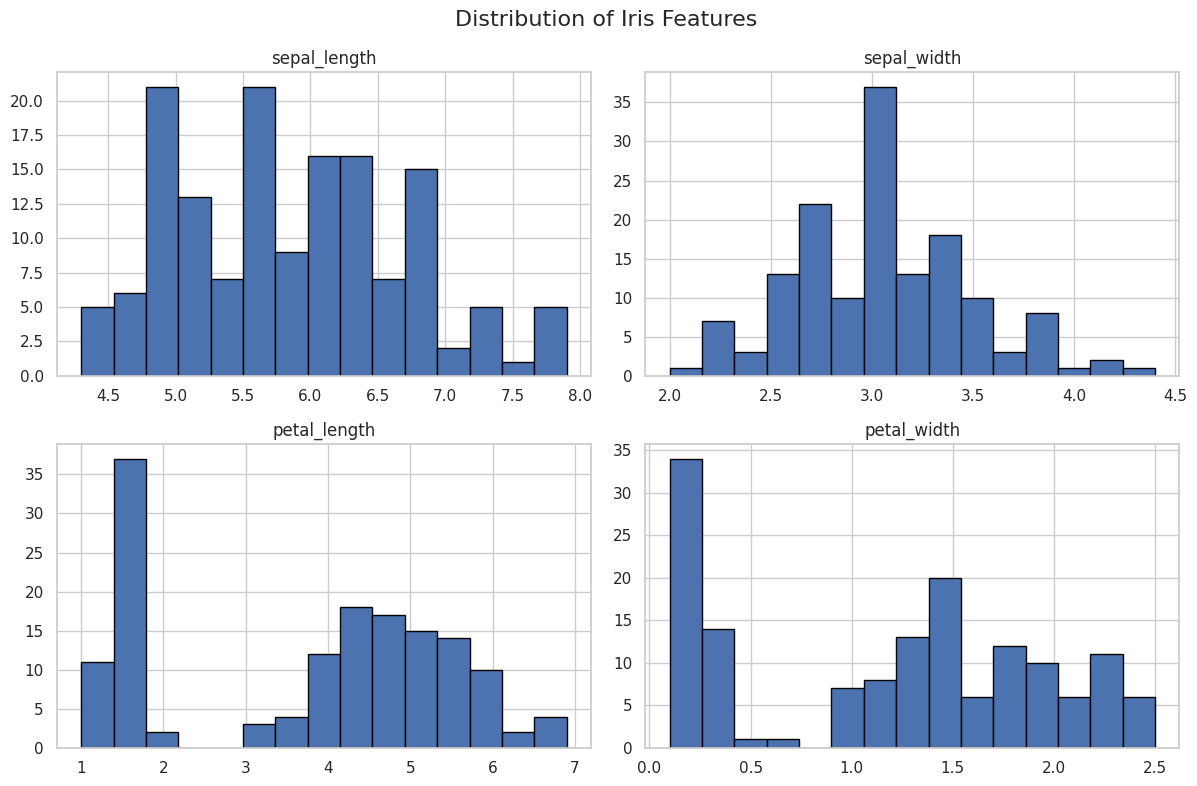

In [30]:
# Create histograms for all numerical input features
X.hist(
    bins=15,
    figsize=(12, 8),
    edgecolor="black"
)

# Add an overall title to the histogram figure
plt.suptitle("Distribution of Iris Features", fontsize=16)

# Adjust spacing between the plots
plt.tight_layout()

# Display the feature distribution plots
plt.show()

# Cell 8: Create a Pairplot Using Seaborn

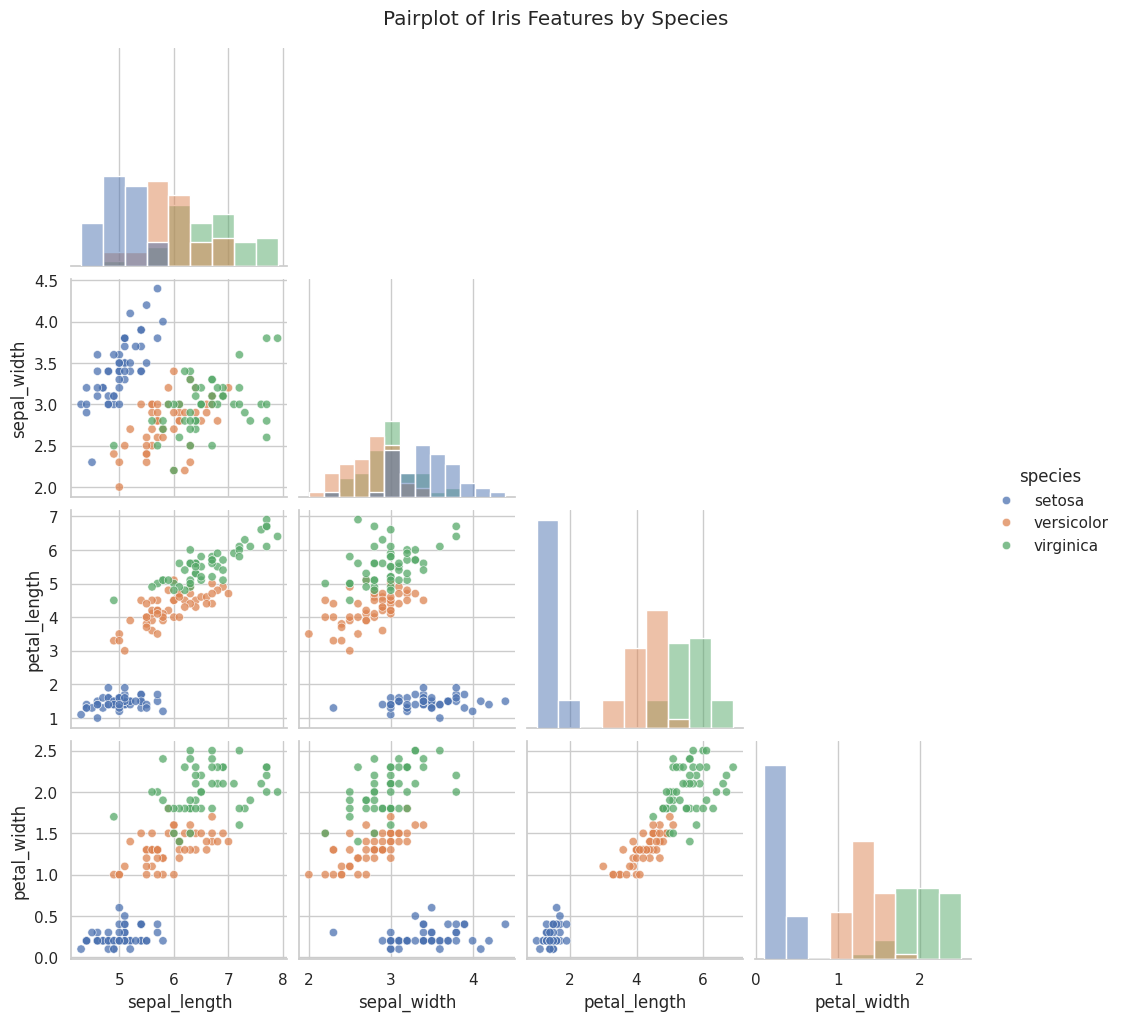

In [31]:
# Combine the numerical features and target labels for visualization
eda_df = X.copy()
eda_df[target_col] = y

# Create pairwise scatter plots for the input features
# Different colors represent different Iris species
sns.pairplot(
    eda_df,
    hue=target_col,
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.75}
)

# Add a title to the pairplot
plt.suptitle(
    "Pairplot of Iris Features by Species",
    y=1.02
)

# Display the pairplot
plt.show()

# Cell 9: Split the Dataset into Training and Testing Sets

In [32]:
# Split the dataset into training and testing subsets
# Use 80% of the samples for training and 20% for testing
# random_state ensures reproducible results
# stratify preserves class proportions in both subsets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the sizes of the training and testing sets
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# Display the class distribution in the training set
print("\nTraining class distribution:")
print(y_train.value_counts())

# Display the class distribution in the testing set
print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 119
Testing samples: 30

Training class distribution:
species
setosa        40
versicolor    40
virginica     39
Name: count, dtype: int64

Testing class distribution:
species
versicolor    10
virginica     10
setosa        10
Name: count, dtype: int64


# Cell 10: Apply StandardScaler

In [33]:
# Initialize the StandardScaler for feature standardization
scaler = StandardScaler()

# Fit the scaler using only the training data
# Transform the training features to have approximately zero mean
# and unit variance
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same transformation to the testing features
# Do not fit the scaler again on the testing data
X_test_scaled = scaler.transform(X_test)

# Display the shapes of the scaled datasets
print("Feature scaling completed successfully!")
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Feature scaling completed successfully!
Scaled training shape: (119, 4)
Scaled testing shape: (30, 4)


# Cell 11: Train Logistic Regression

In [34]:
# Create a machine learning pipeline
# Step 1: Standardize the input features
# Step 2: Train the Logistic Regression classifier

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model using the training dataset
logistic_model.fit(X_train, y_train)

# Predict the species labels for the testing dataset
y_pred_lr = logistic_model.predict(X_test)

# Display a confirmation message
print("Logistic Regression training completed!")

# Display a few predicted labels
print("First ten predictions:")
print(y_pred_lr[:10])

Logistic Regression training completed!
First ten predictions:
['versicolor' 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor'
 'versicolor' 'setosa' 'virginica' 'virginica']


# Cell 12: Train Decision Tree Classifier

In [35]:
# Create a pipeline for the Decision Tree classifier
# StandardScaler is included to maintain a consistent workflow
# max_depth limits tree depth to help control overfitting

decision_tree_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    ))
])

# Train the Decision Tree model using the training data
decision_tree_model.fit(X_train, y_train)

# Predict species labels for the testing data
y_pred_dt = decision_tree_model.predict(X_test)

# Display a confirmation message
print("Decision Tree training completed!")

# Display a few predicted labels
print("First ten predictions:")
print(y_pred_dt[:10])

Decision Tree training completed!
First ten predictions:
['versicolor' 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor'
 'versicolor' 'setosa' 'virginica' 'virginica']


# Cell 13: Evaluate Both Models

In [36]:
# Create an empty list to store model evaluation results
results = []

# Store the predictions generated by each trained model
predictions = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt
}

# Calculate evaluation metrics for each model
for model_name, y_pred in predictions.items():

    # Calculate classification accuracy
    accuracy = accuracy_score(y_test, y_pred)

    # Calculate macro-averaged precision across all classes
    precision = precision_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    # Calculate macro-averaged recall across all classes
    recall = recall_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    # Calculate macro-averaged F1-score across all classes
    f1 = f1_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    # Store the evaluation metrics in a dictionary
    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision (Macro)": precision,
        "Recall (Macro)": recall,
        "F1-score (Macro)": f1
    })

# Convert the evaluation results into a DataFrame
results_df = pd.DataFrame(results)

# Display the model comparison table
print("Model Evaluation Results:")

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision (Macro)": "{:.4f}",
        "Recall (Macro)": "{:.4f}",
        "F1-score (Macro)": "{:.4f}"
    })
)

Model Evaluation Results:


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333


# Cell 14: Generate Classification Reports

In [37]:
# Generate the detailed classification report for Logistic Regression
# The report includes precision, recall, F1-score, and support
print("=" * 60)
print("LOGISTIC REGRESSION - CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred_lr,
        zero_division=0
    )
)

# Generate the detailed classification report for Decision Tree
print("=" * 60)
print("DECISION TREE - CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred_dt,
        zero_division=0
    )
)

LOGISTIC REGRESSION - CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

DECISION TREE - CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



# Cell 15: Plot Logistic Regression Confusion Matrix

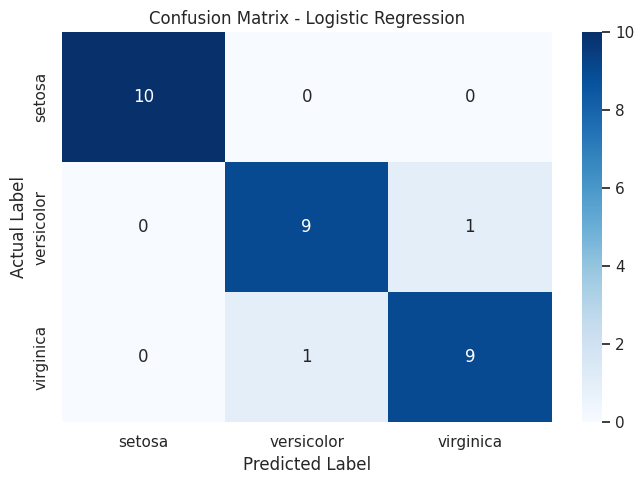

In [38]:
# Obtain the class labels in the model's learned order
class_labels = logistic_model.named_steps["classifier"].classes_

# Calculate the confusion matrix for Logistic Regression
cm_lr = confusion_matrix(
    y_test,
    y_pred_lr,
    labels=class_labels
)

# Create a figure for the confusion matrix heatmap
plt.figure(figsize=(7, 5))

# Visualize correct and incorrect predictions
sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)

# Add the plot title and axis labels
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

# Adjust the layout and display the plot
plt.tight_layout()
plt.show()

# Cell 16: Plot Decision Tree Confusion Matrix

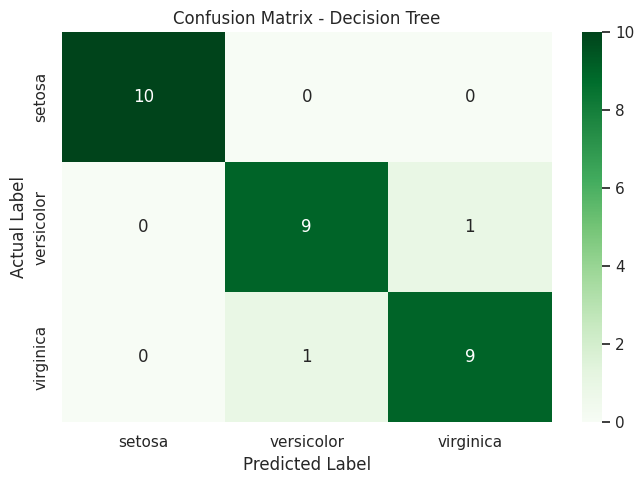

In [39]:
# Retrieve the class labels learned by the Decision Tree classifier
class_labels_dt = decision_tree_model.named_steps["classifier"].classes_

# Calculate the confusion matrix for Decision Tree
cm_dt = confusion_matrix(
    y_test,
    y_pred_dt,
    labels=class_labels_dt
)

# Create a figure for the heatmap
plt.figure(figsize=(7, 5))

# Plot the confusion matrix using a green color palette
sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_labels_dt,
    yticklabels=class_labels_dt
)

# Add a descriptive title and axis labels
plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

# Adjust the layout and display the heatmap
plt.tight_layout()
plt.show()

# Cell 17: Compare Model Performance

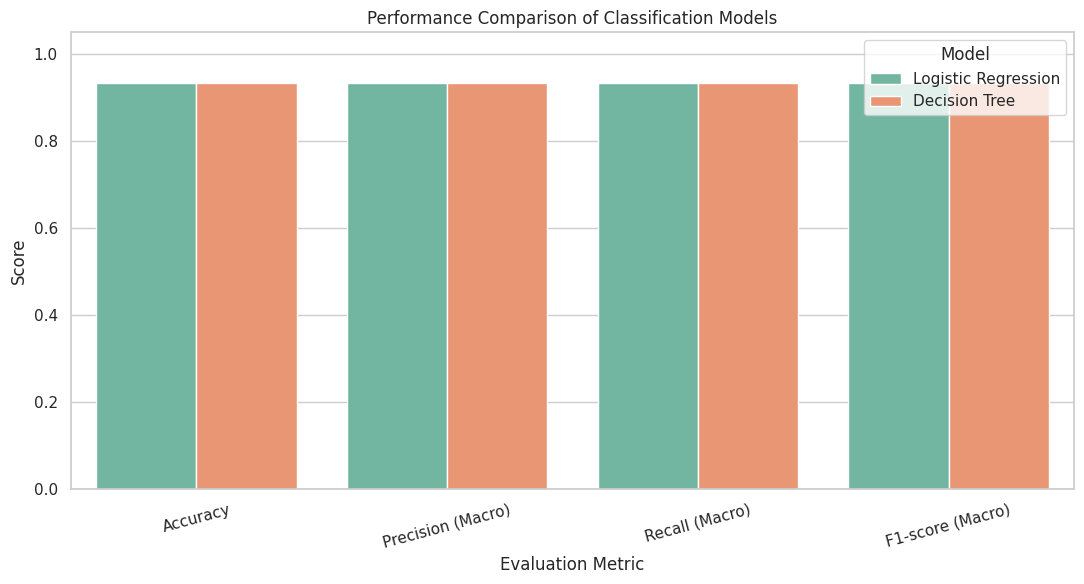

In [40]:
# Define the evaluation metrics to compare
metrics = [
    "Accuracy",
    "Precision (Macro)",
    "Recall (Macro)",
    "F1-score (Macro)"
]

# Convert the results table into a long format for visualization
results_long = results_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

# Create a figure for the comparison chart
plt.figure(figsize=(11, 6))

# Plot the scores of both models for each evaluation metric
sns.barplot(
    data=results_long,
    x="Metric",
    y="Score",
    hue="Model",
    palette="Set2"
)

# Add a descriptive title and axis labels
plt.title("Performance Comparison of Classification Models")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")

# Set the y-axis range for easier comparison
plt.ylim(0, 1.05)

# Rotate the x-axis labels for readability
plt.xticks(rotation=15)

# Display the legend
plt.legend(title="Model")

# Adjust the layout and display the chart
plt.tight_layout()
plt.show()

# Cell 18: Prepare Data for Decision Boundary Visualization

In [41]:
# Identify the petal-related features for visualization
# Petal features are often useful for separating Iris species

petal_features = [
    col for col in X.columns
    if "petal" in col
]

# Select two petal features when available
# Otherwise, use the first two numerical features
if len(petal_features) >= 2:
    selected_features = petal_features[:2]
else:
    selected_features = X.columns[:2].tolist()

# Create a dataset containing only the selected features
X_2d = X[selected_features]

# Split the two-feature dataset into training and testing subsets
# Use the same split settings for reproducibility
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create a two-feature Logistic Regression pipeline
lr_2d = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Create a two-feature Decision Tree pipeline
dt_2d = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    ))
])

# Train both models using only the selected two features
lr_2d.fit(X_train_2d, y_train_2d)
dt_2d.fit(X_train_2d, y_train_2d)

# Display the selected features
print("Features used:", selected_features)
print("Two-feature models trained successfully!")

Features used: ['petal_length', 'petal_width']
Two-feature models trained successfully!


# Cell 19: Plot Decision Boundaries

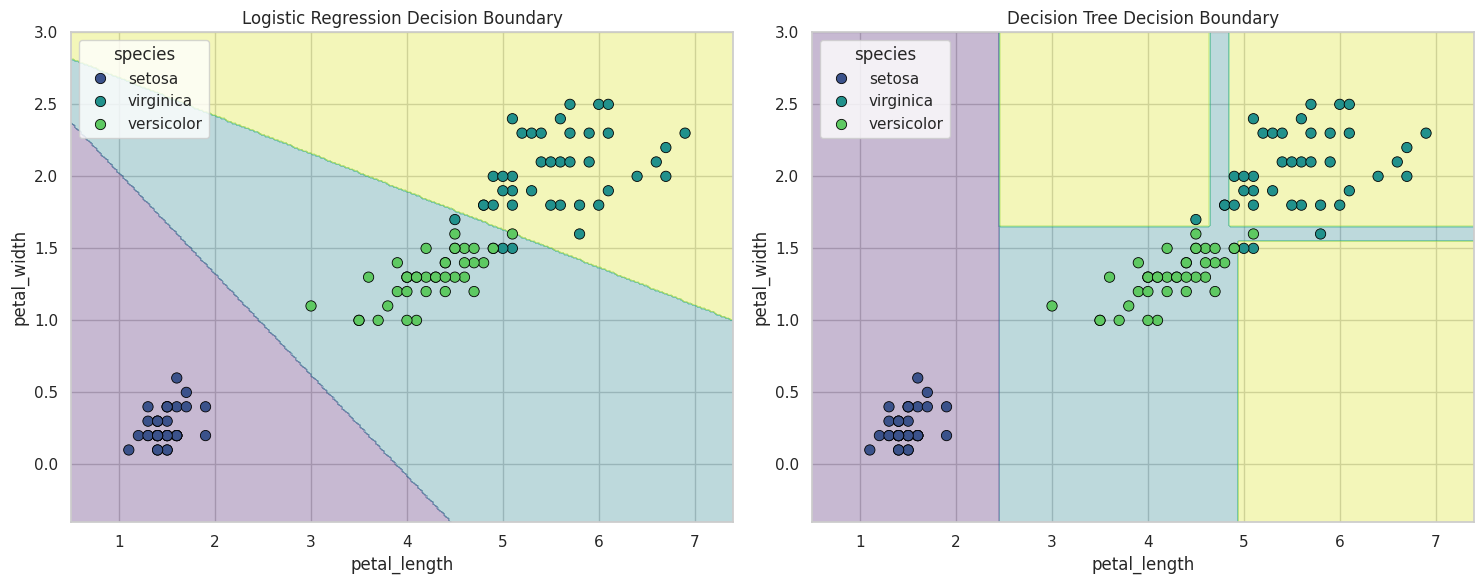

In [42]:
# Define the minimum and maximum values for both selected features
# Add a small margin around the observed feature ranges
x_min = X_2d.iloc[:, 0].min() - 0.5
x_max = X_2d.iloc[:, 0].max() + 0.5

y_min = X_2d.iloc[:, 1].min() - 0.5
y_max = X_2d.iloc[:, 1].max() + 0.5

# Generate a grid of points covering the feature space
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Convert grid coordinates into a DataFrame
# Keep the feature names consistent with the training data
grid = pd.DataFrame(
    np.c_[xx.ravel(), yy.ravel()],
    columns=selected_features
)

# Create side-by-side plots for both classifiers
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Iterate over both models and their corresponding plot axes
for ax, model, title in [
    (axes[0], lr_2d, "Logistic Regression Decision Boundary"),
    (axes[1], dt_2d, "Decision Tree Decision Boundary")
]:

    # Predict the class for every point on the grid
    Z = model.predict(grid)

    # Convert class labels into numeric values for contour plotting
    class_to_num = {
        label: i for i, label in enumerate(model.classes_)
    }

    Z_num = np.array([
        class_to_num[label] for label in Z
    ])

    # Reshape predictions to match the grid dimensions
    Z_num = Z_num.reshape(xx.shape)

    # Plot the predicted class regions
    ax.contourf(
        xx,
        yy,
        Z_num,
        alpha=0.3,
        cmap="viridis"
    )

    # Overlay the training samples using their actual class labels
    sns.scatterplot(
        x=X_train_2d.iloc[:, 0],
        y=X_train_2d.iloc[:, 1],
        hue=y_train_2d,
        palette="viridis",
        s=55,
        edgecolor="black",
        ax=ax,
        legend=True
    )

    # Add the plot title and axis labels
    ax.set_title(title)
    ax.set_xlabel(selected_features[0])
    ax.set_ylabel(selected_features[1])

# Adjust spacing between the two plots
plt.tight_layout()

# Display both decision boundary visualizations
plt.show()

#Cell 20: Select the Best Baseline Model

In [43]:
# Identify the model with the highest macro-averaged F1-score
best_index = results_df["F1-score (Macro)"].idxmax()

# Retrieve the evaluation results of the selected model
best_row = results_df.loc[best_index]

# Display the selected model and its evaluation metrics
print("=" * 60)
print("BEST BASELINE MODEL")
print("=" * 60)

print("Model:", best_row["Model"])
print(f"Accuracy: {best_row['Accuracy']:.4f}")
print(f"Precision (Macro): {best_row['Precision (Macro)']:.4f}")
print(f"Recall (Macro): {best_row['Recall (Macro)']:.4f}")
print(f"F1-score (Macro): {best_row['F1-score (Macro)']:.4f}")

# Explain the selection criterion
print("\nSelection criterion: Highest Macro F1-score")

BEST BASELINE MODEL
Model: Logistic Regression
Accuracy: 0.9333
Precision (Macro): 0.9333
Recall (Macro): 0.9333
F1-score (Macro): 0.9333

Selection criterion: Highest Macro F1-score


# Cell 21: Save Evaluation Results to Google Drive

In [44]:
# Define an output folder in Google Drive
output_dir = "/content/drive/MyDrive/Iris_Classification_Results"

# Create the output folder if it does not already exist
os.makedirs(output_dir, exist_ok=True)

# Save the model comparison metrics as a CSV file
results_df.to_csv(
    os.path.join(output_dir, "model_comparison.csv"),
    index=False
)

# Generate classification reports for both trained models
report_lr = classification_report(
    y_test,
    y_pred_lr,
    zero_division=0
)

report_dt = classification_report(
    y_test,
    y_pred_dt,
    zero_division=0
)

# Save the classification reports to a text file
with open(
    os.path.join(output_dir, "classification_reports.txt"),
    "w",
    encoding="utf-8"
) as f:

    # Write the Logistic Regression report
    f.write("LOGISTIC REGRESSION CLASSIFICATION REPORT\n")
    f.write(report_lr)

    # Add spacing between the reports
    f.write("\n\n")

    # Write the Decision Tree report
    f.write("DECISION TREE CLASSIFICATION REPORT\n")
    f.write(report_dt)

# Save the confusion matrix plots as image files
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.savefig(
    os.path.join(output_dir, "confusion_matrix_logistic_regression.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.close()

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_labels_dt,
    yticklabels=class_labels_dt
)
plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.savefig(
    os.path.join(output_dir, "confusion_matrix_decision_tree.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.close()

# Display the output directory and the saved files
print("Results saved successfully!")
print("Output directory:", output_dir)

print("\nSaved files:")
for file_name in os.listdir(output_dir):
    print(file_name)

Results saved successfully!
Output directory: /content/drive/MyDrive/Iris_Classification_Results

Saved files:
model_comparison.csv
classification_reports.txt
confusion_matrix_logistic_regression.png
confusion_matrix_decision_tree.png


Cell 22: Final Project Conclusion

In [45]:
# Identify the best-performing baseline model by macro F1-score
best_row = results_df.loc[
    results_df["F1-score (Macro)"].idxmax()
]

# Print a summary of the completed machine learning experiment
print("=" * 65)
print("PROJECT CONCLUSION")
print("=" * 65)

# Summarize the models used in the experiment
print(
    "\nIn this project, Logistic Regression and Decision Tree "
    "classifiers were trained and evaluated on the Iris dataset."
)

# Summarize the dataset splitting strategy
print(
    "\nThe dataset was split into 80% training data and "
    "20% testing data."
)

# Summarize the feature preprocessing approach
print(
    "StandardScaler was used within machine learning pipelines "
    "to standardize features without data leakage."
)

# Report the model with the highest macro F1-score
print(f"\nBest baseline model: {best_row['Model']}")

# Display the final evaluation metrics
print(f"Accuracy: {best_row['Accuracy']:.4f}")
print(f"Precision (Macro): {best_row['Precision (Macro)']:.4f}")
print(f"Recall (Macro): {best_row['Recall (Macro)']:.4f}")
print(f"F1-score (Macro): {best_row['F1-score (Macro)']:.4f}")

# Summarize the visualizations generated
print(
    "\nEDA plots, classification reports, confusion matrix heatmaps, "
    "performance comparisons, and decision boundaries were generated."
)

# Provide a data-driven conclusion rather than assuming a fixed winner
print(
    "\nThe final model should be selected based on the observed "
    "evaluation metrics and classification errors."
)

PROJECT CONCLUSION

In this project, Logistic Regression and Decision Tree classifiers were trained and evaluated on the Iris dataset.

The dataset was split into 80% training data and 20% testing data.
StandardScaler was used within machine learning pipelines to standardize features without data leakage.

Best baseline model: Logistic Regression
Accuracy: 0.9333
Precision (Macro): 0.9333
Recall (Macro): 0.9333
F1-score (Macro): 0.9333

EDA plots, classification reports, confusion matrix heatmaps, performance comparisons, and decision boundaries were generated.

The final model should be selected based on the observed evaluation metrics and classification errors.


In [46]:
# Import required libraries
import os
import zipfile
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

from google.colab import files
from sklearn.metrics import confusion_matrix

# Create an output directory in Google Drive
output_dir = "/content/drive/MyDrive/Iris_Classification_Results"
os.makedirs(output_dir, exist_ok=True)

# Create a temporary directory for visualization files
plot_dir = "/content/iris_visualizations"
os.makedirs(plot_dir, exist_ok=True)

# Store the generated plot file paths
plot_files = []

# Define a helper function to save high-resolution plots
def save_plot(filename):
    # Build the full output path
    file_path = os.path.join(plot_dir, filename)

    # Save the current figure as a high-resolution PNG
    plt.savefig(
        file_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    # Close the figure to free memory
    plt.close()

    # Store the file path
    plot_files.append(file_path)

    # Copy the image to Google Drive
    drive_path = os.path.join(output_dir, filename)
    import shutil
    shutil.copy2(file_path, drive_path)

    print("Saved:", filename)


print("Starting visualization export...")

Starting visualization export...


In [47]:
# 1. Class distribution plot
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x=target_col,
    hue=target_col,
    palette="viridis",
    legend=False
)

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Number of Samples")
plt.tight_layout()

save_plot("01_class_distribution.png")


# 2. Feature distribution histograms
axes = X.hist(
    bins=15,
    figsize=(12, 8),
    edgecolor="black"
)

plt.suptitle("Distribution of Iris Features", fontsize=16)
plt.tight_layout()

save_plot("02_feature_distributions.png")


# 3. Seaborn pairplot
eda_df = X.copy()
eda_df[target_col] = y

pair_grid = sns.pairplot(
    eda_df,
    hue=target_col,
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.75}
)

pair_grid.fig.suptitle(
    "Pairplot of Iris Features by Species",
    y=1.02
)

# Save the pairplot separately because it is a Seaborn FacetGrid
pair_path = os.path.join(
    plot_dir,
    "03_pairplot.png"
)

pair_grid.fig.savefig(
    pair_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.close(pair_grid.fig)
plot_files.append(pair_path)

import shutil
shutil.copy2(
    pair_path,
    os.path.join(output_dir, "03_pairplot.png")
)

print("Saved: 03_pairplot.png")


# 4. Logistic Regression confusion matrix
class_labels = logistic_model.named_steps["classifier"].classes_

cm_lr = confusion_matrix(
    y_test,
    y_pred_lr,
    labels=class_labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

save_plot("04_confusion_matrix_logistic_regression.png")


# 5. Decision Tree confusion matrix
class_labels_dt = decision_tree_model.named_steps["classifier"].classes_

cm_dt = confusion_matrix(
    y_test,
    y_pred_dt,
    labels=class_labels_dt
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_labels_dt,
    yticklabels=class_labels_dt
)

plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

save_plot("05_confusion_matrix_decision_tree.png")


# 6. Model performance comparison
metrics = [
    "Accuracy",
    "Precision (Macro)",
    "Recall (Macro)",
    "F1-score (Macro)"
]

results_long = results_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=results_long,
    x="Metric",
    y="Score",
    hue="Model",
    palette="Set2"
)

plt.title("Model Performance Comparison")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.tight_layout()

save_plot("06_model_performance_comparison.png")


# 7. Decision boundary visualization
# Use the two-feature models trained in Cell 18

x_min = X_2d.iloc[:, 0].min() - 0.5
x_max = X_2d.iloc[:, 0].max() + 0.5
y_min = X_2d.iloc[:, 1].min() - 0.5
y_max = X_2d.iloc[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = pd.DataFrame(
    np.c_[xx.ravel(), yy.ravel()],
    columns=selected_features
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, model, title in [
    (axes[0], lr_2d, "Logistic Regression Decision Boundary"),
    (axes[1], dt_2d, "Decision Tree Decision Boundary")
]:
    # Predict classes for all points in the feature grid
    Z = model.predict(grid)

    # Convert predicted labels into numeric class identifiers
    class_to_num = {
        label: i for i, label in enumerate(model.classes_)
    }

    Z_num = np.array([
        class_to_num[label] for label in Z
    ]).reshape(xx.shape)

    # Display the predicted decision regions
    ax.contourf(
        xx,
        yy,
        Z_num,
        alpha=0.3,
        cmap="viridis"
    )

    # Display the actual training samples
    sns.scatterplot(
        data=X_train_2d,
        x=selected_features[0],
        y=selected_features[1],
        hue=y_train_2d,
        palette="viridis",
        edgecolor="black",
        ax=ax,
        legend=True
    )

    ax.set_title(title)
    ax.set_xlabel(selected_features[0])
    ax.set_ylabel(selected_features[1])

plt.tight_layout()

save_plot("07_decision_boundaries.png")


# Display the total number of saved visualizations
print("\nAll visualizations generated successfully!")
print("Total PNG files:", len(plot_files))
print("Google Drive folder:", output_dir)

Saved: 01_class_distribution.png
Saved: 02_feature_distributions.png
Saved: 03_pairplot.png
Saved: 04_confusion_matrix_logistic_regression.png
Saved: 05_confusion_matrix_decision_tree.png
Saved: 06_model_performance_comparison.png
Saved: 07_decision_boundaries.png

All visualizations generated successfully!
Total PNG files: 7
Google Drive folder: /content/drive/MyDrive/Iris_Classification_Results


In [48]:
# Define the ZIP archive path
zip_path = "/content/Iris_Classification_Visualizations.zip"

# Create a ZIP archive containing all generated PNG files
with zipfile.ZipFile(
    zip_path,
    mode="w",
    compression=zipfile.ZIP_DEFLATED
) as zip_file:

    # Add each visualization to the ZIP archive
    for file_path in plot_files:
        zip_file.write(
            file_path,
            arcname=os.path.basename(file_path)
        )

# Display the generated files
print("ZIP file created successfully!")
print("\nIncluded visualizations:")

for file_path in plot_files:
    print("-", os.path.basename(file_path))

# Automatically initiate the ZIP download in Google Colab
files.download(zip_path)

ZIP file created successfully!

Included visualizations:
- 01_class_distribution.png
- 02_feature_distributions.png
- 03_pairplot.png
- 04_confusion_matrix_logistic_regression.png
- 05_confusion_matrix_decision_tree.png
- 06_model_performance_comparison.png
- 07_decision_boundaries.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>